In [1]:
# %% [markdown]
# # Cardiovascular Disease Prediction: Cost-Sensitive Screening with Threshold Optimization
# Author: Md. Anwarul Karim

# %% 1. Imports and configuration
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, brier_score_loss
)

SEED = 42
TARGET_RECALL = 0.80
os.makedirs("figures", exist_ok=True)
plt.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", palette="muted")

print("All Librray Runs Perfectly")

All Librray Runs Perfectly


Raw shape: (308854, 19)
Cleaned shape: (308754, 17)
CVD prevalence: 8.09%
Duplicate rows kept: 100


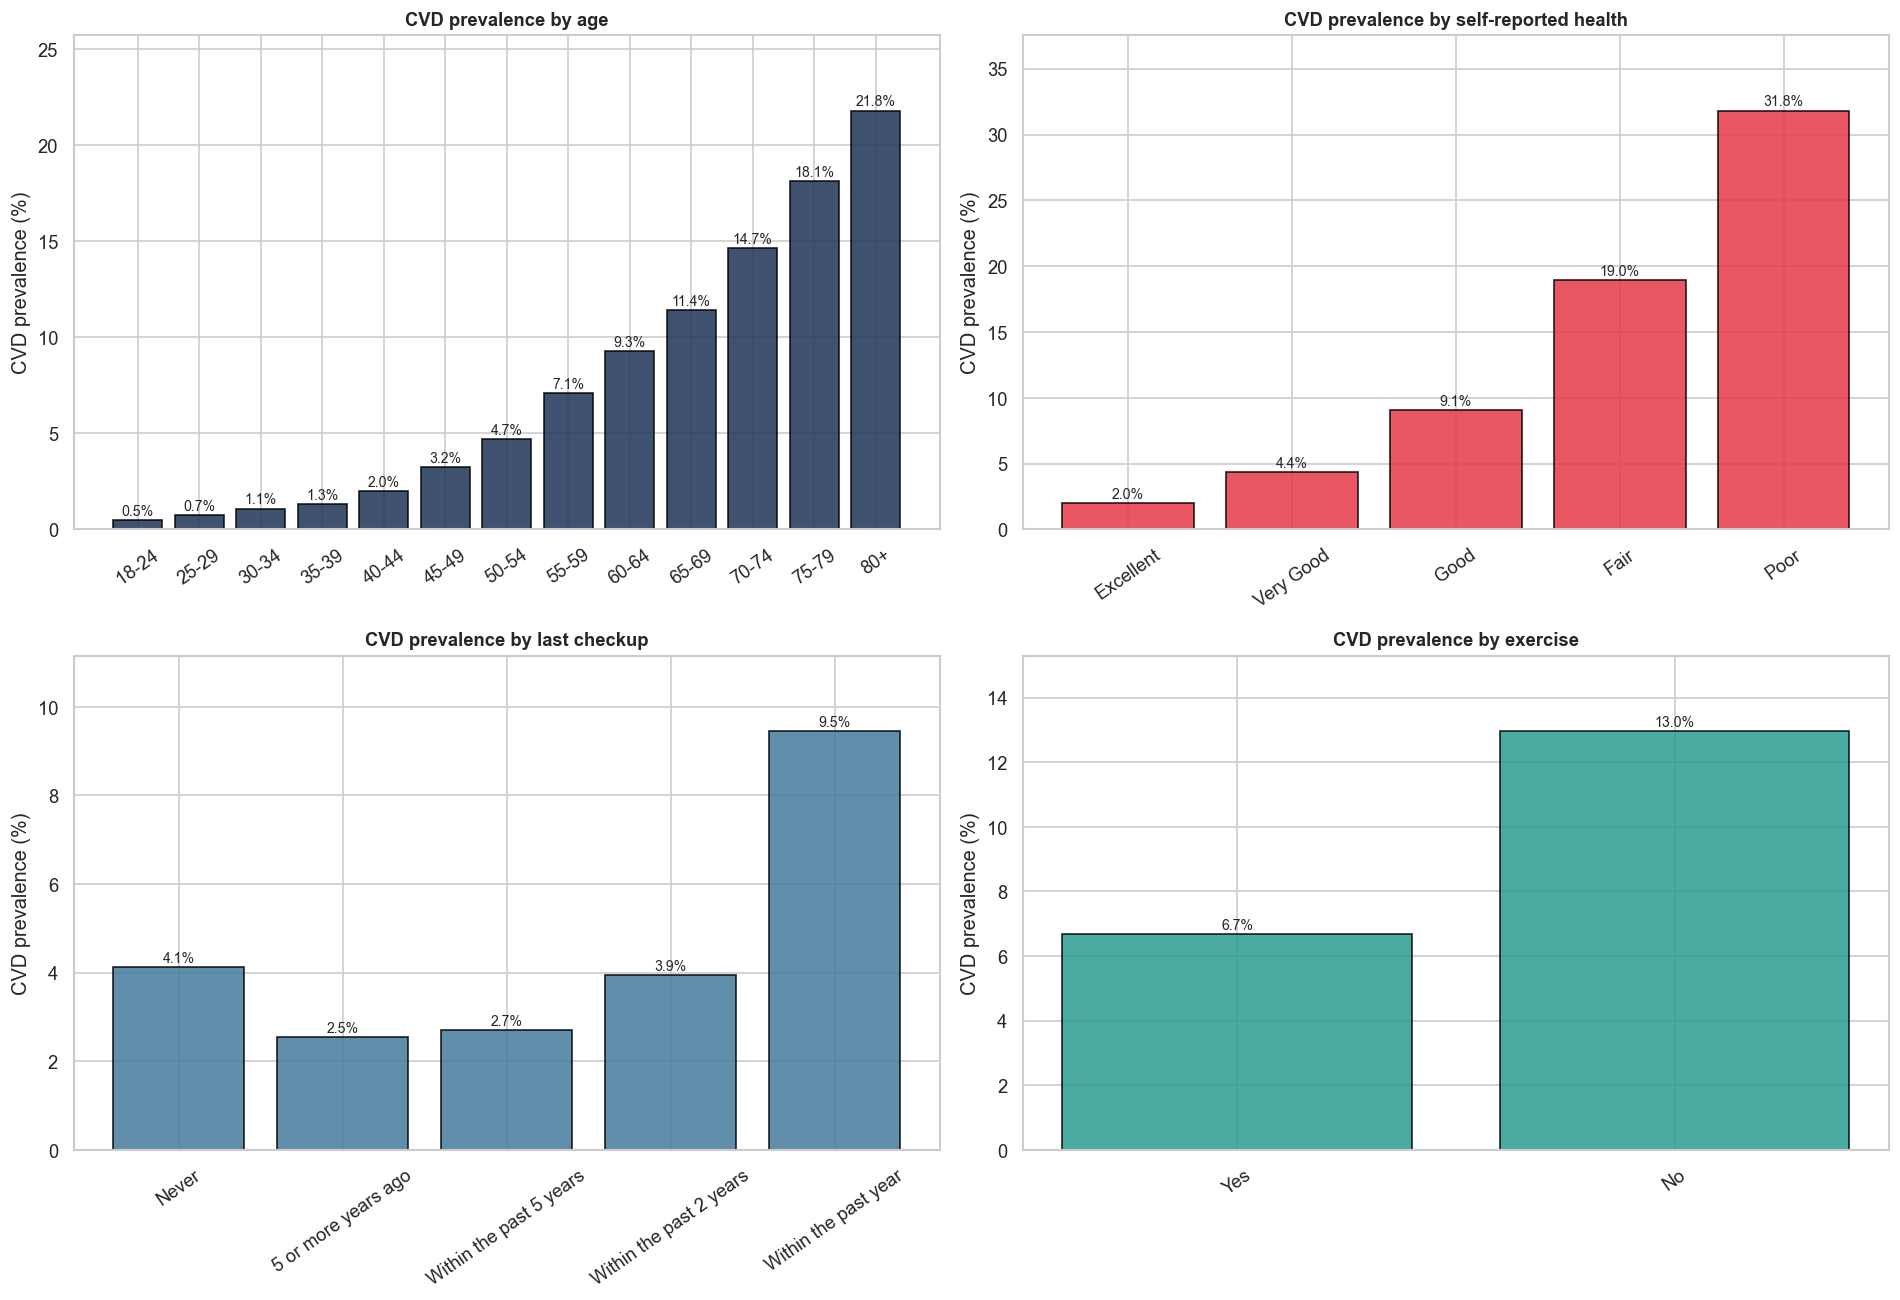

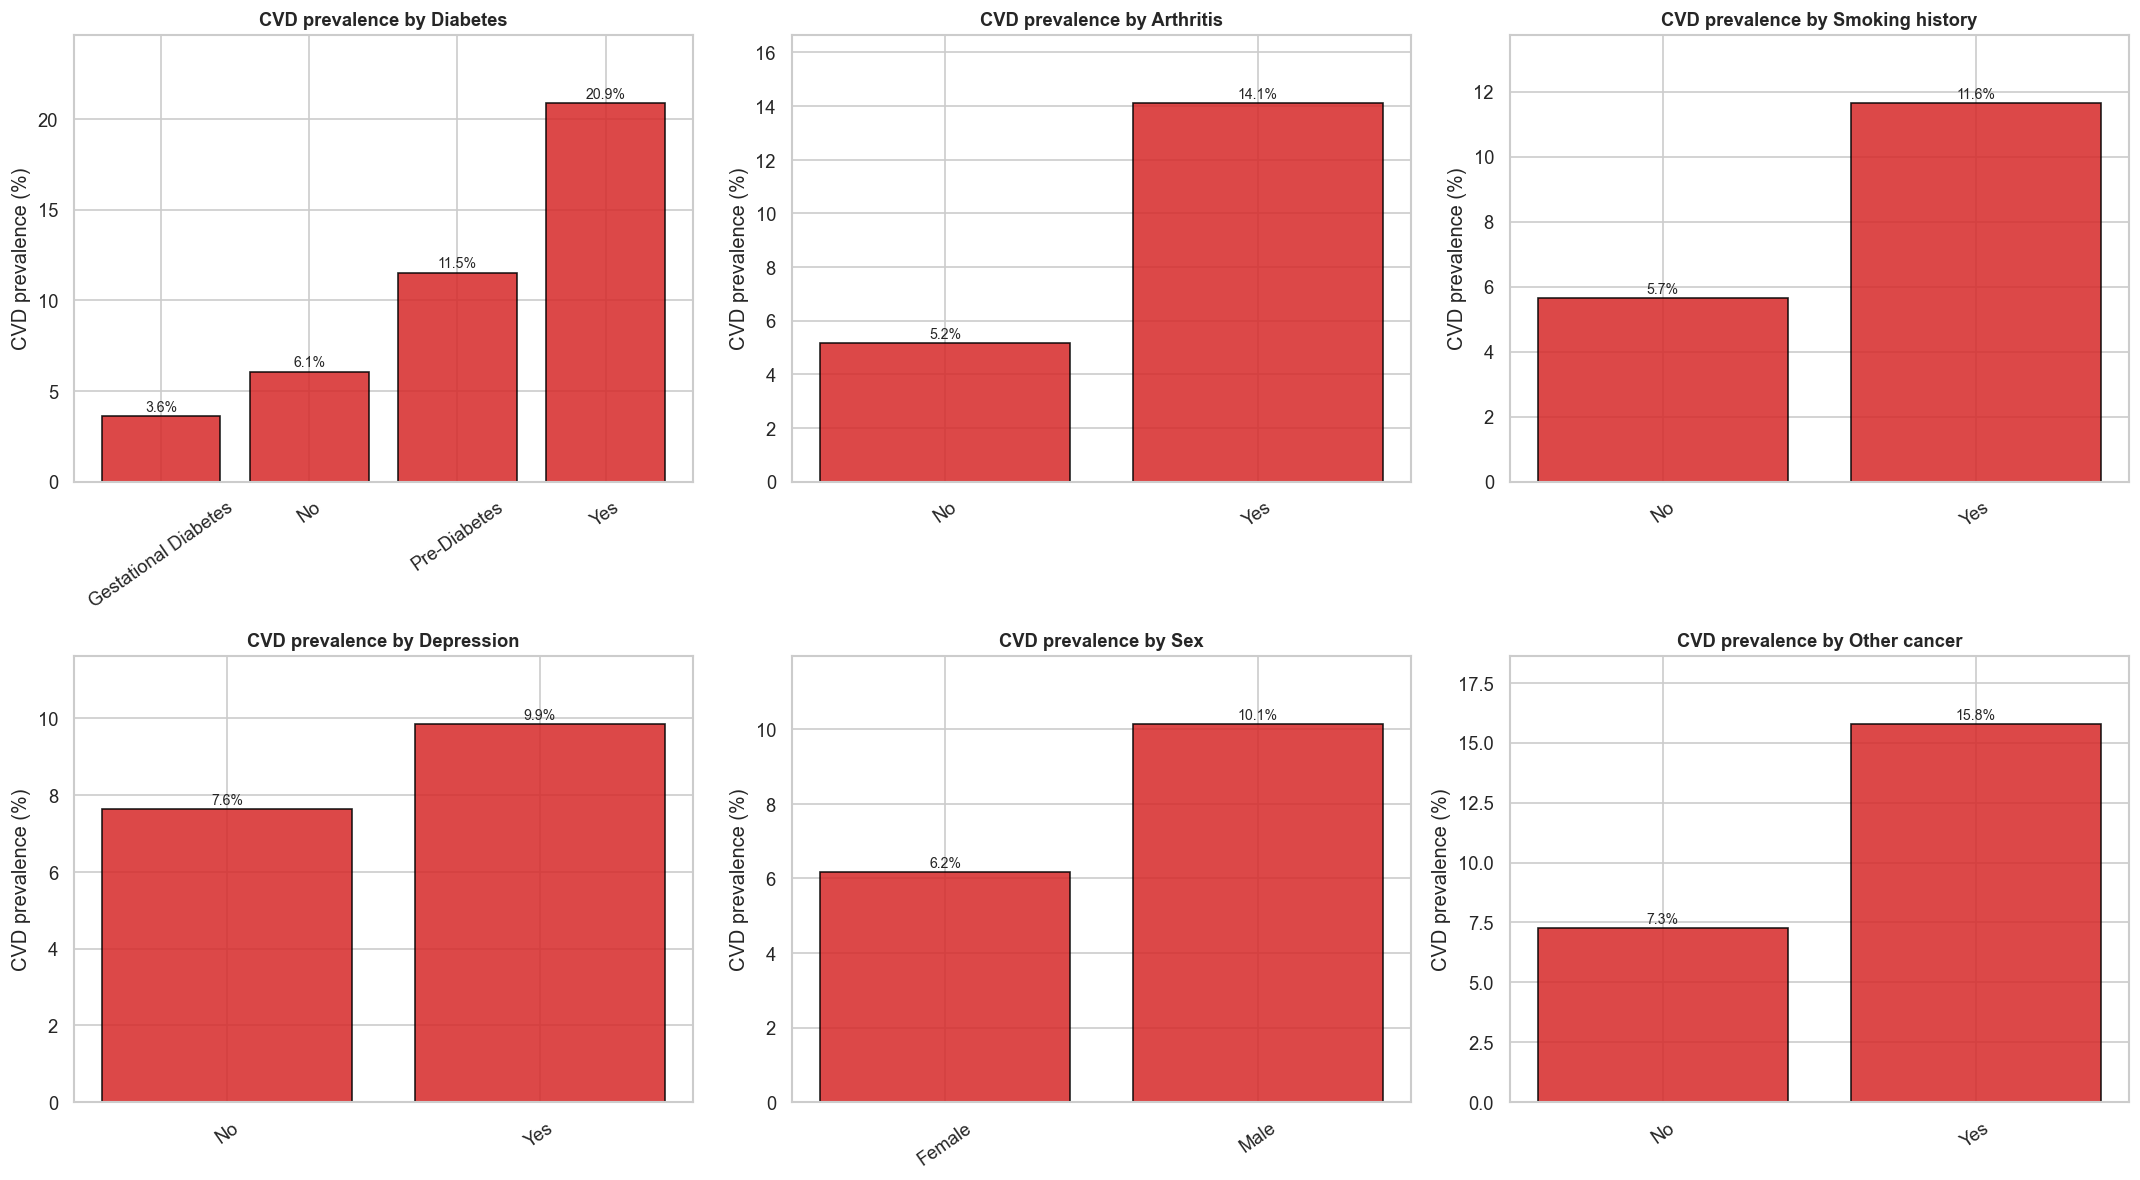

In [2]:
# ==============================================================================
# BLOCK 2: DATA LOADING & BIOLOGICALLY GROUNDED CLEANING
# ==============================================================================
# %% 2. Load data and clean
df = pd.read_csv("CVD_cleaned.csv")
print(f"Raw shape: {df.shape}")

# BMI already captures height and weight
df = df.drop(columns=["Weight_(kg)", "Height_(cm)"])

df["Diabetes"] = df["Diabetes"].map({
    "No": "No",
    "No, pre-diabetes or borderline diabetes": "Pre-Diabetes",
    "Yes, but female told only during pregnancy": "Gestational Diabetes",
    "Yes": "Yes",
})

# Remove only biologically implausible BMI values (no blind IQR deletion)
df = df[(df["BMI"] >= 12.0) & (df["BMI"] <= 75.0)].copy()
print(f"Cleaned shape: {df.shape}")
print(f"CVD prevalence: {(df['Heart_Disease'] == 'Yes').mean() * 100:.2f}%")
print(f"Duplicate rows kept: {df.duplicated().sum()}")

# %% 3. EDA: within-group prevalence, P(CVD | feature)
age_order = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
             "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]
health_order = ["Excellent", "Very Good", "Good", "Fair", "Poor"]
checkup_order = ["Never", "5 or more years ago", "Within the past 5 years",
                 "Within the past 2 years", "Within the past year"]


def plot_prevalence(data, feature, ax, title, order=None, color="#d62828"):
    rate = (data["Heart_Disease"].eq("Yes").groupby(data[feature]).mean() * 100)
    rate = rate.reindex(order) if order is not None else rate.sort_values()
    bars = ax.bar(rate.index.astype(str), rate.values, color=color, edgecolor="black", alpha=0.85)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel("CVD prevalence (%)")
    ax.tick_params(axis="x", rotation=35)
    for b in bars:
        ax.annotate(f"{b.get_height():.1f}%", (b.get_x() + b.get_width() / 2, b.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)
    ax.set_ylim(0, rate.max() * 1.18)


fig, ax = plt.subplots(2, 2, figsize=(16, 11))
plot_prevalence(df, "Age_Category", ax[0, 0], "CVD prevalence by age", age_order, "#1d3557")
plot_prevalence(df, "General_Health", ax[0, 1], "CVD prevalence by self-reported health", health_order, "#e63946")
plot_prevalence(df, "Checkup", ax[1, 0], "CVD prevalence by last checkup", checkup_order, "#457b9d")
plot_prevalence(df, "Exercise", ax[1, 1], "CVD prevalence by exercise", None, "#2a9d8f")
plt.tight_layout()
plt.savefig("figures/eda_prevalence_1.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(2, 3, figsize=(18, 10))
for a, (col, ttl) in zip(ax.ravel(), [("Diabetes", "Diabetes"), ("Arthritis", "Arthritis"),
                                      ("Smoking_History", "Smoking history"), ("Depression", "Depression"),
                                      ("Sex", "Sex"), ("Other_Cancer", "Other cancer")]):
    plot_prevalence(df, col, a, f"CVD prevalence by {ttl}")
plt.tight_layout()
plt.savefig("figures/eda_prevalence_2.png", bbox_inches="tight")
plt.show()

In [3]:
# ==============================================================================
# BLOCK 4: CLINICAL PREVALENCE RATE EDA (ELIMINATING BASE-RATE FALLACY)
# ==============================================================================

# %% 4. Encoding and stratified split
binary = ["Exercise", "Skin_Cancer", "Other_Cancer", "Depression", "Arthritis",
          "Smoking_History", "Heart_Disease"]
mappings = {
    "General_Health": {"Poor": 0, "Fair": 1, "Good": 2, "Very Good": 3, "Excellent": 4},
    "Checkup": {c: i for i, c in enumerate(checkup_order)},
    "Age_Category": {a: i for i, a in enumerate(age_order)},
    "Sex": {"Female": 0, "Male": 1},
    **{c: {"No": 0, "Yes": 1} for c in binary},
}
enc = df.copy()
for col, mp in mappings.items():
    enc[col] = enc[col].map(mp)
assert enc.isna().sum().sum() == 0, "Unmapped category found"

X = enc.drop(columns="Heart_Disease")
y = enc["Heart_Disease"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,} ({int(y_test.sum()):,} positives)")


# %% 5. Leak-free preprocessing and models
num_cols = ["BMI", "Alcohol_Consumption", "Fruit_Consumption",
            "Green_Vegetables_Consumption", "FriedPotato_Consumption"]
nom_cols = ["Diabetes"]
ord_cols = [c for c in X.columns if c not in num_cols + nom_cols]


def make_preprocessor(drop_cols=()):
    nc = [c for c in num_cols if c not in drop_cols]
    oc = [c for c in ord_cols if c not in drop_cols]
    return ColumnTransformer([
        ("num", StandardScaler(), nc),
        ("nom", OneHotEncoder(drop="first", sparse_output=False), nom_cols),
        ("ord", "passthrough", oc),
    ])


preprocessor = make_preprocessor()
hgb_params = dict(max_iter=250, learning_rate=0.05, max_depth=6,
                  min_samples_leaf=30, random_state=SEED)

models = {
    "Logistic Regression (balanced)": Pipeline([
        ("prep", preprocessor),
        ("clf", LogisticRegression(class_weight="balanced", C=1.0, max_iter=1000, random_state=SEED))]),
    "Decision Tree (pruned, balanced)": Pipeline([
        ("prep", preprocessor),
        ("clf", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50,
                                       class_weight="balanced", random_state=SEED))]),
    "Random Forest (regularized, balanced)": Pipeline([
        ("prep", preprocessor),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=25,
                                       max_features="sqrt", class_weight="balanced",
                                       n_jobs=-1, random_state=SEED))]),
    "HistGradientBoosting (cost-sensitive)": Pipeline([
        ("prep", preprocessor),
        ("clf", HistGradientBoostingClassifier(class_weight="balanced", **hgb_params))]),
}


def evaluate(name, y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "Model": name, "Threshold": round(float(thr), 4),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
        "Recall": recall_score(y_true, pred),
        "Specificity": tn / (tn + fp),
        "Precision": precision_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "F2": fbeta_score(y_true, pred, beta=2.0),
        "Accuracy": accuracy_score(y_true, pred),
        "Brier": brier_score_loss(y_true, prob),
    }


records, probs = [], {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    probs[name] = pipe.predict_proba(X_test)[:, 1]
    records.append(evaluate(name, y_test, probs[name], 0.50))

# %% 6. Calibration + threshold chosen WITHOUT touching the test set
# Out-of-fold calibrated probabilities on the TRAINING data pick tau*.
# The test set is used only once, to report the result.
cal_name = "Calibrated HGB (tau* from training OOF)"


def make_calibrated():
    base = Pipeline([("prep", make_preprocessor()),
                     ("clf", HistGradientBoostingClassifier(**hgb_params))])
    return CalibratedClassifierCV(base, method="isotonic", cv=3)


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = cross_val_predict(make_calibrated(), X_train, y_train, cv=skf,
                        method="predict_proba", n_jobs=-1)[:, 1]

_, rec, thr = precision_recall_curve(y_train, oof)
tau = thr[np.where(rec[:-1] >= TARGET_RECALL)[0][-1]]
print(f"tau* (chosen on training OOF) = {tau:.4f}")

final_model = make_calibrated().fit(X_train, y_train)
probs[cal_name] = final_model.predict_proba(X_test)[:, 1]
records.append(evaluate(cal_name, y_test, probs[cal_name], tau))

results = pd.DataFrame(records).set_index("Model")
print("\n=== TEST-SET RESULTS ===")
print(results.round(4).to_string())
results.round(4).to_csv("figures/results_table.csv")

Train: 247,003 | Test: 61,751 (4,993 positives)
tau* (chosen on training OOF) = 0.0874

=== TEST-SET RESULTS ===
                                         Threshold  ROC-AUC  PR-AUC  Recall  Specificity  Precision      F1      F2  Accuracy   Brier
Model                                                                                                                                
Logistic Regression (balanced)              0.5000   0.8331  0.2995  0.7901       0.7310     0.2053  0.3260  0.5034    0.7358  0.1726
Decision Tree (pruned, balanced)            0.5000   0.8247  0.2871  0.7951       0.7108     0.1947  0.3129  0.4918    0.7176  0.1763
Random Forest (regularized, balanced)       0.5000   0.8336  0.2955  0.7901       0.7286     0.2039  0.3241  0.5016    0.7336  0.1650
HistGradientBoosting (cost-sensitive)       0.5000   0.8353  0.3005  0.8077       0.7203     0.2026  0.3239  0.5056    0.7274  0.1711
Calibrated HGB (tau* from training OOF)     0.0874   0.8355  0.3003  0.7997       0


=== Bootstrap 95% CI (final model) ===
ROC-AUC      0.8356  [0.8309, 0.8402]
PR-AUC       0.3006  [0.2892, 0.3130]
Recall       0.7999  [0.7896, 0.8102]
Specificity  0.7271  [0.7239, 0.7308]
Precision    0.2048  [0.1991, 0.2106]


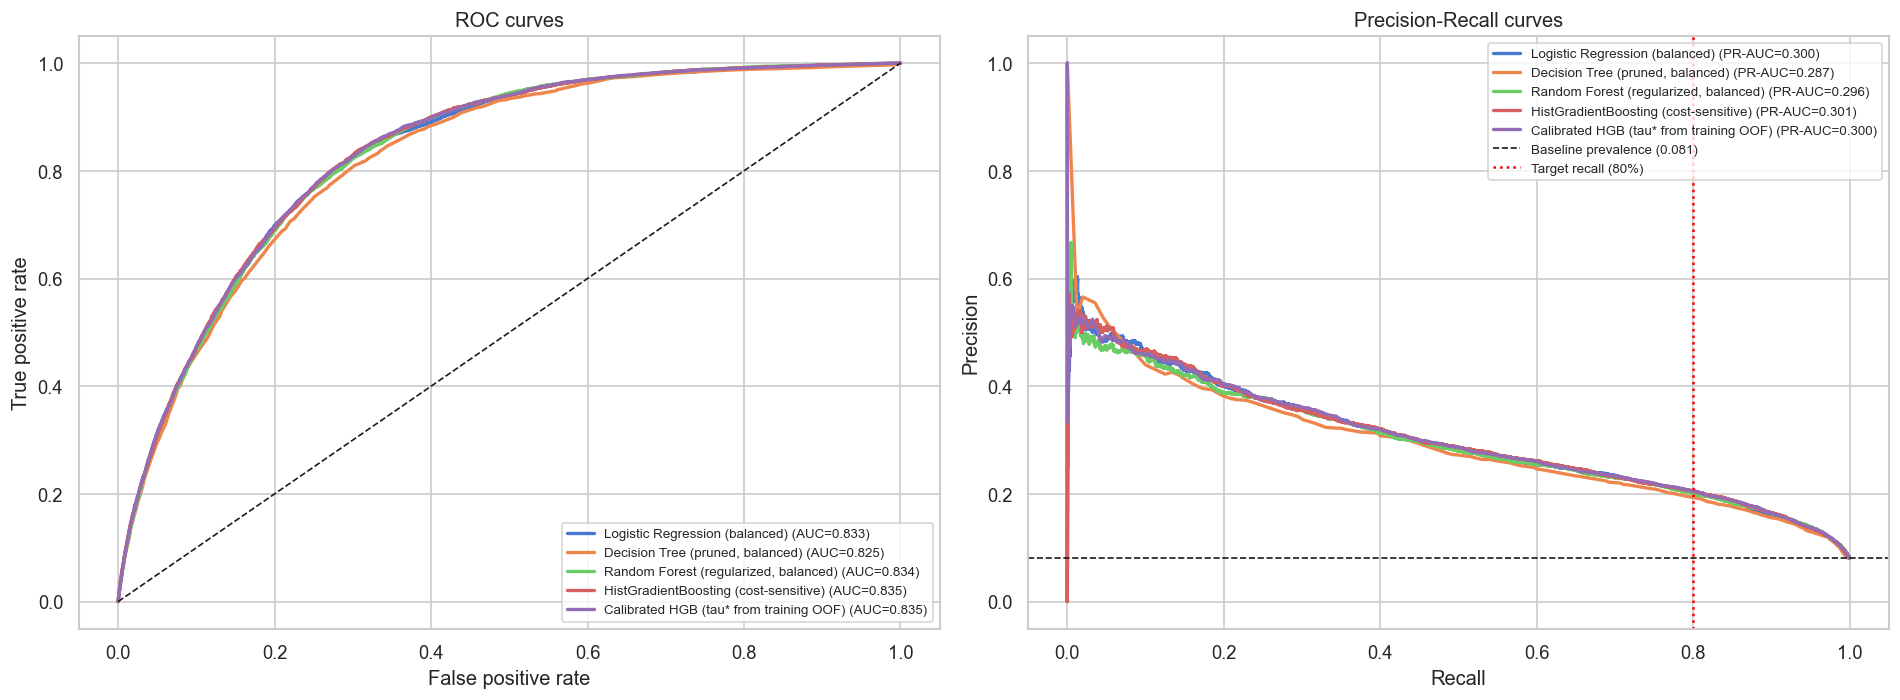

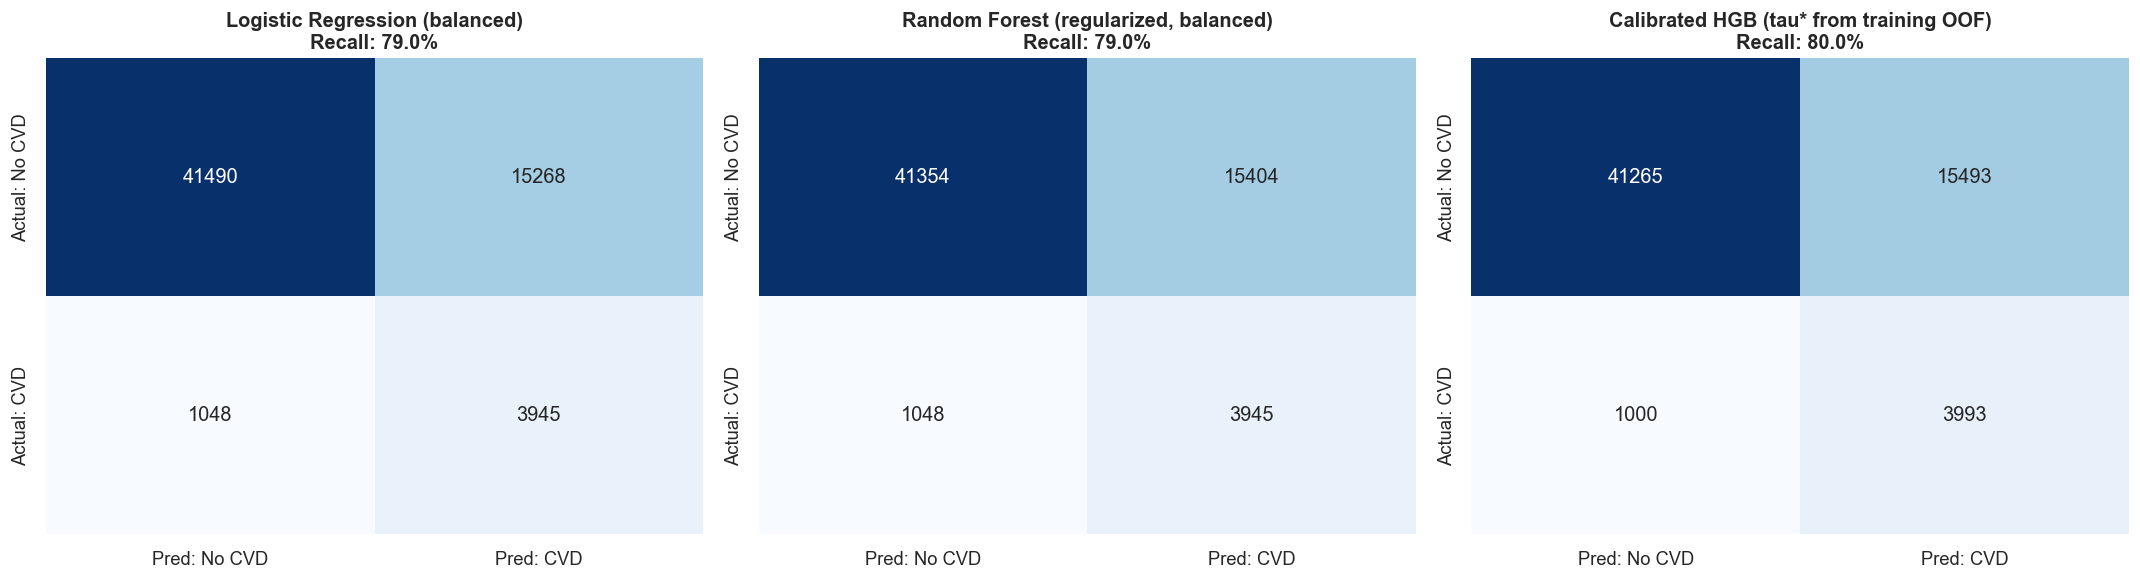

In [10]:
# ==============================================================================
# BLOCK 7: PROBABILITY CALIBRATION & CLINICAL THRESHOLD OPTIMIZATION (80% RECALL)
# ==============================================================================

# %% 7. Uncertainty: bootstrap 95% CIs on the final model
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
pt = probs[cal_name]
boot = {"ROC-AUC": [], "PR-AUC": [], "Recall": [], "Specificity": [], "Precision": []}
for _ in range(500):
    i = rng.integers(0, len(yt), len(yt))
    yb, pb = yt[i], pt[i]
    pred = pb >= tau
    boot["ROC-AUC"].append(roc_auc_score(yb, pb))
    boot["PR-AUC"].append(average_precision_score(yb, pb))
    boot["Recall"].append(pred[yb == 1].mean())
    boot["Specificity"].append((~pred[yb == 0]).mean())
    boot["Precision"].append(yb[pred].mean())
print("\n=== Bootstrap 95% CI (final model) ===")
for k, v in boot.items():
    lo, hi = np.percentile(v, [2.5, 97.5])
    print(f"{k:12s} {np.mean(v):.4f}  [{lo:.4f}, {hi:.4f}]")

# %% 8. ROC / PR curves and confusion matrices
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for name, p in probs.items():
    f, t, _ = roc_curve(y_test, p)
    ax[0].plot(f, t, lw=2, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, lw=2, label=f"{name} (PR-AUC={average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
ax[0].legend(loc="lower right", fontsize=8)
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Baseline prevalence ({y_test.mean():.3f})")
ax[1].axvline(TARGET_RECALL, color="red", ls=":", lw=1.5, label="Target recall (80%)")
ax[1].set(title="Precision-Recall curves", xlabel="Recall", ylabel="Precision")
ax[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig("figures/roc_pr_curves.png", bbox_inches="tight")
plt.show()

picked = ["Logistic Regression (balanced)", "Random Forest (regularized, balanced)", cal_name]
thr_for = {n: 0.5 for n in probs}
thr_for[cal_name] = tau
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for a, n in zip(axes, picked):
    pred = (probs[n] >= thr_for[n]).astype(int)
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["Pred: No CVD", "Pred: CVD"], yticklabels=["Actual: No CVD", "Actual: CVD"])
    a.set_title(f"{n}\nRecall: {recall_score(y_test, pred) * 100:.1f}%", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", bbox_inches="tight")
plt.show()



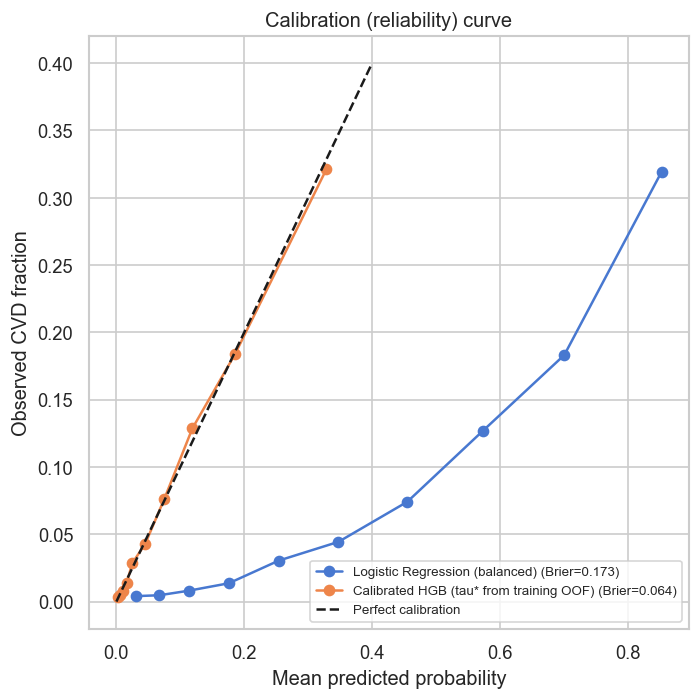

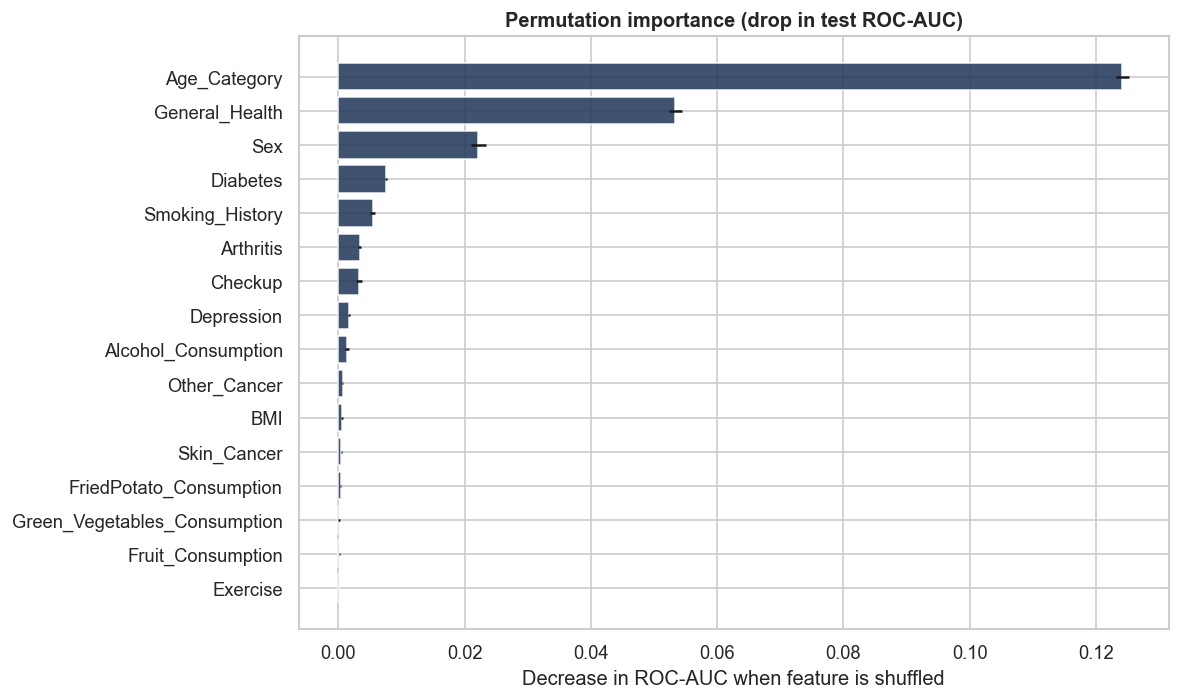

        Feature   Mean    Std
   Age_Category 0.1242 0.0011
 General_Health 0.0534 0.0010
            Sex 0.0222 0.0012
       Diabetes 0.0076 0.0002
Smoking_History 0.0054 0.0004
      Arthritis 0.0034 0.0002
        Checkup 0.0033 0.0005
     Depression 0.0017 0.0002

ROC-AUC with General_Health:    0.8353
ROC-AUC without General_Health: 0.8174
PR-AUC  without General_Health: 0.2637


In [4]:
# ==============================================================================
# BLOCK 9: PERMUTATION FEATURE IMPORTANCE (CLINICAL EXPLAINABILITY)
# ==============================================================================
# %% 9. Calibration check
fig, ax = plt.subplots(figsize=(6, 6))
for name in ["Logistic Regression (balanced)", cal_name]:
    frac, mean_p = calibration_curve(y_test, probs[name], n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", label=f"{name} (Brier={brier_score_loss(y_test, probs[name]):.3f})")
ax.plot([0, 0.4], [0, 0.4], "k--", label="Perfect calibration")
ax.set(title="Calibration (reliability) curve", xlabel="Mean predicted probability",
       ylabel="Observed CVD fraction")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/calibration_curve.png", bbox_inches="tight")
plt.show()

# %% 10. Permutation importance
hgb_pipe = models["HistGradientBoosting (cost-sensitive)"]
perm = permutation_importance(hgb_pipe, X_test, y_test, n_repeats=5,
                              random_state=SEED, scoring="roc_auc", n_jobs=-1)
imp = pd.DataFrame({"Feature": X.columns, "Mean": perm.importances_mean,
                    "Std": perm.importances_std}).sort_values("Mean")
plt.figure(figsize=(10, 6))
plt.barh(imp["Feature"], imp["Mean"], xerr=imp["Std"], color="#1d3557", alpha=0.85)
plt.title("Permutation importance (drop in test ROC-AUC)", fontweight="bold")
plt.xlabel("Decrease in ROC-AUC when feature is shuffled")
plt.tight_layout()
plt.savefig("figures/permutation_importance.png", bbox_inches="tight")
plt.show()
print(imp.sort_values("Mean", ascending=False).head(8).round(4).to_string(index=False))

# %% 11. Ablation: how much does self-rated health carry?
ablate = Pipeline([("prep", make_preprocessor(drop_cols=["General_Health"])),
                   ("clf", HistGradientBoostingClassifier(class_weight="balanced", **hgb_params))])
ablate.fit(X_train.drop(columns="General_Health"), y_train)
p_ab = ablate.predict_proba(X_test.drop(columns="General_Health"))[:, 1]
full = roc_auc_score(y_test, probs["HistGradientBoosting (cost-sensitive)"])
print(f"\nROC-AUC with General_Health:    {full:.4f}")
print(f"ROC-AUC without General_Health: {roc_auc_score(y_test, p_ab):.4f}")
print(f"PR-AUC  without General_Health: {average_precision_score(y_test, p_ab):.4f}")